In [3]:
import os
import random
import torch
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter
from scipy.spatial.transform import Rotation as R

# --------- Config ---------
SVF_FILE = "/scratch/anirudhkaushik/svf_metadata.csv"  # must have columns: Subject, Visit, SVF_Path
SAVE_DIR = "/scratch/anirudhkaushik/synthetic_deformations"
NUM_SYNTHETIC = 5
SVF_SHAPE = (3, 128, 128, 128)  # expected shape for SVFs

# Augmentation hyperparameters
ELASTIC_SIGMA_RANGE = (3.0, 6.0)
SCALE_RANGE = (1.2, 2.0)
AFFINE_RANGE = 0.05
ELASTIC_STRENGTH = 0.05
ROTATION_DEG = 10


# --------- Utils ---------
def apply_rotation_to_svf(svf, rot_matrix):
    c, h, w, d = svf.shape
    svf_flat = svf.reshape(3, -1)
    svf_rotated_flat = rot_matrix @ svf_flat
    return svf_rotated_flat.reshape(3, h, w, d)


def generate_augmented_svf(base_svf):
    svf_aug = base_svf.copy()

    # 1. Scaling
    scale = random.uniform(*SCALE_RANGE)
    svf_aug *= scale

    # 2. Elastic noise
    sigma = random.uniform(*ELASTIC_SIGMA_RANGE)
    elastic_noise = np.random.randn(*svf_aug.shape)
    elastic_noise = np.stack([
        gaussian_filter(elastic_noise[i], sigma=sigma) for i in range(3)
    ])
    svf_aug += ELASTIC_STRENGTH * elastic_noise

    # 3. Affine ramp
    affine_field = np.zeros_like(svf_aug)
    spatial_shape = svf_aug.shape[1:]
    for i in range(3):
        ramp = np.linspace(-1, 1, spatial_shape[i]) * random.uniform(-AFFINE_RANGE, AFFINE_RANGE)
        ramp_shape = [1, 1, 1]
        ramp_shape[i] = spatial_shape[i]
        ramp = ramp.reshape(ramp_shape)
        ramp_field = np.broadcast_to(ramp, spatial_shape)
        affine_field[i] = ramp_field
    svf_aug += affine_field

    # 4. Physically correct vector rotation
    angles = [random.uniform(-ROTATION_DEG, ROTATION_DEG) for _ in range(3)]
    rot_matrix = R.from_euler('xyz', angles, degrees=True).as_matrix()
    svf_aug = apply_rotation_to_svf(svf_aug, rot_matrix)

    return torch.tensor(svf_aug, dtype=torch.float32)



svf_df = pd.read_csv(SVF_FILE)
if not {'Subject', 'Visit', 'SVF_Path'}.issubset(svf_df.columns):
    raise ValueError("SVF file must have columns: Subject, Visit, SVF_Path")

available_paths = svf_df['SVF_Path'].tolist()
print(f"Loaded {len(available_paths)} real SVF paths.")

list_svf = []

real_path = available_paths[0]
for i in range(NUM_SYNTHETIC):
    try:
        base_svf = torch.load(real_path).numpy()
        if base_svf.shape != SVF_SHAPE:
            print(f"Skipping malformed SVF: {real_path}")
            continue
    except Exception as e:
        print(f"Failed to load {real_path}: {e}")
        continue

    synthetic_svf = generate_augmented_svf(base_svf)
    save_path = os.path.join(SAVE_DIR, f"synthetic_svf_{i:04d}.pt")
    list_svf.append(save_path)




Loaded 1576 real SVF paths.


2025-04-25 22:52:28.064582: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

def create_grid(shape, spacing=10):
    """Create a grid pattern image with given shape and spacing."""
    h, w = shape
    grid = np.ones((h, w))
    
    # Create horizontal and vertical grid lines
    for i in range(0, h, spacing):
        grid[i, :] = 0
    
    for j in range(0, w, spacing):
        grid[:, j] = 0
        
    return grid

def warp_grid_with_svf(grid, svf, steps=10):
    """
    Warp a grid using a stationary velocity field (SVF) through scaling and squaring.
    
    Args:
        grid: 2D numpy array representing the grid image
        svf: 3D tensor of shape [2, H, W] for x and y components of the velocity field
        steps: Number of scaling and squaring steps
    
    Returns:
        Warped grid as a 2D numpy array
    """
    h, w = grid.shape
    y_coords, x_coords = np.meshgrid(np.arange(h), np.arange(w), indexing='ij')
    coords = np.stack([y_coords, x_coords], axis=0)
    
    # Scaling step
    scaled_svf = svf / (2**steps)
    
    # Initialize the displacement field with the scaled SVF
    disp_field = scaled_svf.clone()
    
    # Squaring steps - compose the displacement field with itself repeatedly
    for _ in range(steps):
        # Get coordinates for sampling
        y_vals = torch.arange(h).unsqueeze(1).expand(-1, w).float()
        x_vals = torch.arange(w).unsqueeze(0).expand(h, -1).float()
        
        # Add displacement to get sampling coordinates
        y_disp = y_vals + disp_field[0]
        x_disp = x_vals + disp_field[1]
        
        # Ensure coordinates are within bounds (optional but safer)
        y_disp = torch.clamp(y_disp, 0, h-1)
        x_disp = torch.clamp(x_disp, 0, w-1)
        
        # Sample current displacement field at the displaced coordinates
        disp_y = torch.nn.functional.grid_sample(
            disp_field[0].unsqueeze(0).unsqueeze(0),
            torch.stack([2*x_disp/(w-1)-1, 2*y_disp/(h-1)-1], dim=-1).unsqueeze(0),
            mode='bilinear', align_corners=True
        ).squeeze()
        
        disp_x = torch.nn.functional.grid_sample(
            disp_field[1].unsqueeze(0).unsqueeze(0),
            torch.stack([2*x_disp/(w-1)-1, 2*y_disp/(h-1)-1], dim=-1).unsqueeze(0),
            mode='bilinear', align_corners=True
        ).squeeze()
        
        # Compose displacement fields
        disp_field = torch.stack([disp_y, disp_x], dim=0) + disp_field
    
    # Apply final displacement field to grid coordinates
    warped_coords = coords + disp_field.cpu().numpy()
    
    # Use scipy's map_coordinates for interpolation
    warped_grid = map_coordinates(grid, warped_coords, order=1)
    
    return warped_grid

def visualize_svf_grid(svf, slice_axis=2, slice_idx=None, grid_spacing=None, figsize=(15, 5)):
    """
    Visualize a 3D SVF by showing how it warps a regular grid on a 2D slice.
    
    Args:
        svf: A tensor of shape [3, H, W, D] (can be torch.Tensor or numpy.ndarray)
        slice_axis: Which axis to slice along (0=sagittal, 1=coronal, 2=axial)
        slice_idx: Index of the slice to visualize (defaults to middle slice)
        grid_spacing: Spacing between grid lines (defaults to shape/20)
        figsize: Size of the figure to create
        
    Returns:
        fig: The matplotlib figure object
    """
    # Convert numpy array to torch tensor if needed
    if isinstance(svf, np.ndarray):
        svf = torch.tensor(svf, dtype=torch.float32)
    
    # Handle different tensor dimensions
    if len(svf.shape) == 5 and svf.shape[0] == 1:  # [1, 3, H, W, D]
        svf = svf.squeeze(0)
    
    # Extract shape information
    c, h, w, d = svf.shape
    
    # Set default slice index to middle of volume
    if slice_idx is None:
        if slice_axis == 0:
            slice_idx = h // 2
        elif slice_axis == 1:
            slice_idx = w // 2
        else:  # slice_axis == 2
            slice_idx = d // 2
    
    # Extract the 2D slice and its corresponding velocity components
    if slice_axis == 0:  # Sagittal slice (fixed x)
        svf_slice = torch.stack([svf[1, slice_idx, :, :], svf[2, slice_idx, :, :]])  # y,z components
        slice_shape = (w, d)
    elif slice_axis == 1:  # Coronal slice (fixed y)
        svf_slice = torch.stack([svf[0, :, slice_idx, :], svf[2, :, slice_idx, :]])  # x,z components
        slice_shape = (h, d)
    else:  # slice_axis == 2, Axial slice (fixed z)
        svf_slice = torch.stack([svf[0, :, :, slice_idx], svf[1, :, :, slice_idx]])  # x,y components
        slice_shape = (h, w)
    
    # Set default grid spacing if not provided
    if grid_spacing is None:
        grid_spacing = max(slice_shape) // 64
    
    # Create original grid
    original_grid = create_grid(slice_shape, spacing=grid_spacing)
    
    # Warp the grid
    warped_grid = warp_grid_with_svf(original_grid, svf_slice)
    
    # Plot results
    fig, axes = plt.subplots(1, 3, figsize=figsize)
    
    # Plot original grid
    axes[0].imshow(original_grid, cmap='gray')
    axes[0].set_title('Original Grid')
    axes[0].axis('off')
    
    # Determine which plane we're viewing
    plane_names = {0: 'Sagittal', 1: 'Coronal', 2: 'Axial'}
    plane_name = plane_names[slice_axis]
    
    # Plot SVF visualization (quiver plot)
    # Subsample for cleaner visualization
    step = max(slice_shape) // 30
    y_grid, x_grid = np.mgrid[0:slice_shape[0]:step, 0:slice_shape[1]:step]
    u = svf_slice[0, y_grid, x_grid].cpu().numpy()
    v = svf_slice[1, y_grid, x_grid].cpu().numpy()
    
    axes[1].imshow(original_grid, cmap='gray', alpha=0.5)
    axes[1].quiver(x_grid, y_grid, u, v, color='red')
    axes[1].set_title(f'Vector Field ({plane_name} Slice {slice_idx})')
    axes[1].axis('off')
    
    # Plot warped grid
    axes[2].imshow(warped_grid, cmap='gray')
    axes[2].set_title('Warped Grid')
    axes[2].axis('off')
    
    plt.tight_layout()
    return fig

def visualize_svf_file(svf_path, **kwargs):
    """
    Load an SVF from a file path and visualize it.
    
    Args:
        svf_path: Path to the SVF file (.pt format)
        **kwargs: Additional arguments to pass to visualize_svf_grid
        
    Returns:
        fig: The matplotlib figure object
    """
    try:
        svf = torch.load(svf_path)
        return visualize_svf_grid(svf, **kwargs)
    except Exception as e:
        print(f"Error loading or visualizing SVF from {svf_path}: {e}")
        return None

def visualize_multiple_svfs(svf_paths, num_cols=3, **kwargs):
    """
    Visualize multiple SVFs in a grid layout.
    
    Args:
        svf_paths: List of paths to SVF files
        num_cols: Number of columns in the grid layout
        **kwargs: Additional arguments to pass to visualize_svf_grid
        
    Returns:
        fig: The matplotlib figure object
    """
    num_svfs = len(svf_paths)
    num_rows = (num_svfs + num_cols - 1) // num_cols
    
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(5*num_cols, 5*num_rows))
    axes = axes.flatten() if num_rows * num_cols > 1 else [axes]
    
    for i, path in enumerate(svf_paths):
        if i < len(axes):
            try:
                svf = torch.load(path)
                
                # Get slice information from kwargs or use defaults
                slice_axis = kwargs.get('slice_axis', 2)
                slice_idx = kwargs.get('slice_idx', None)
                
                # Extract shape information
                c, h, w, d = svf.shape
                
                # Set default slice index if not provided
                if slice_idx is None:
                    if slice_axis == 0:
                        slice_idx = h // 2
                    elif slice_axis == 1:
                        slice_idx = w // 2
                    else:  # slice_axis == 2
                        slice_idx = d // 2
                
                # Extract the 2D slice based on slice_axis
                if slice_axis == 0:  # Sagittal
                    svf_slice = torch.stack([svf[1, slice_idx, :, :], svf[2, slice_idx, :, :]])
                    slice_shape = (w, d)
                elif slice_axis == 1:  # Coronal
                    svf_slice = torch.stack([svf[0, :, slice_idx, :], svf[2, :, slice_idx, :]])
                    slice_shape = (h, d)
                else:  # Axial (slice_axis == 2)
                    svf_slice = torch.stack([svf[0, :, :, slice_idx], svf[1, :, :, slice_idx]])
                    slice_shape = (h, w)
                
                # Create and warp grid
                grid_spacing = kwargs.get('grid_spacing', max(slice_shape) // 64)
                original_grid = create_grid(slice_shape, spacing=grid_spacing)
                warped_grid = warp_grid_with_svf(original_grid, svf_slice)
                
                # Plot result
                axes[i].imshow(warped_grid, cmap='gray', alpha=0.7)
                axes[i].set_title(f'SVF {i+1}: {path.split("/")[-1]}', fontsize=10)
                axes[i].axis('off')
            
            except Exception as e:
                axes[i].text(0.5, 0.5, f"Error: {str(e)}", 
                           horizontalalignment='center', verticalalignment='center')
                axes[i].axis('off')
    
    # Hide unused subplots
    for j in range(num_svfs, len(axes)):
        axes[j].axis('off')
    
    plt.tight_layout()
    return fig



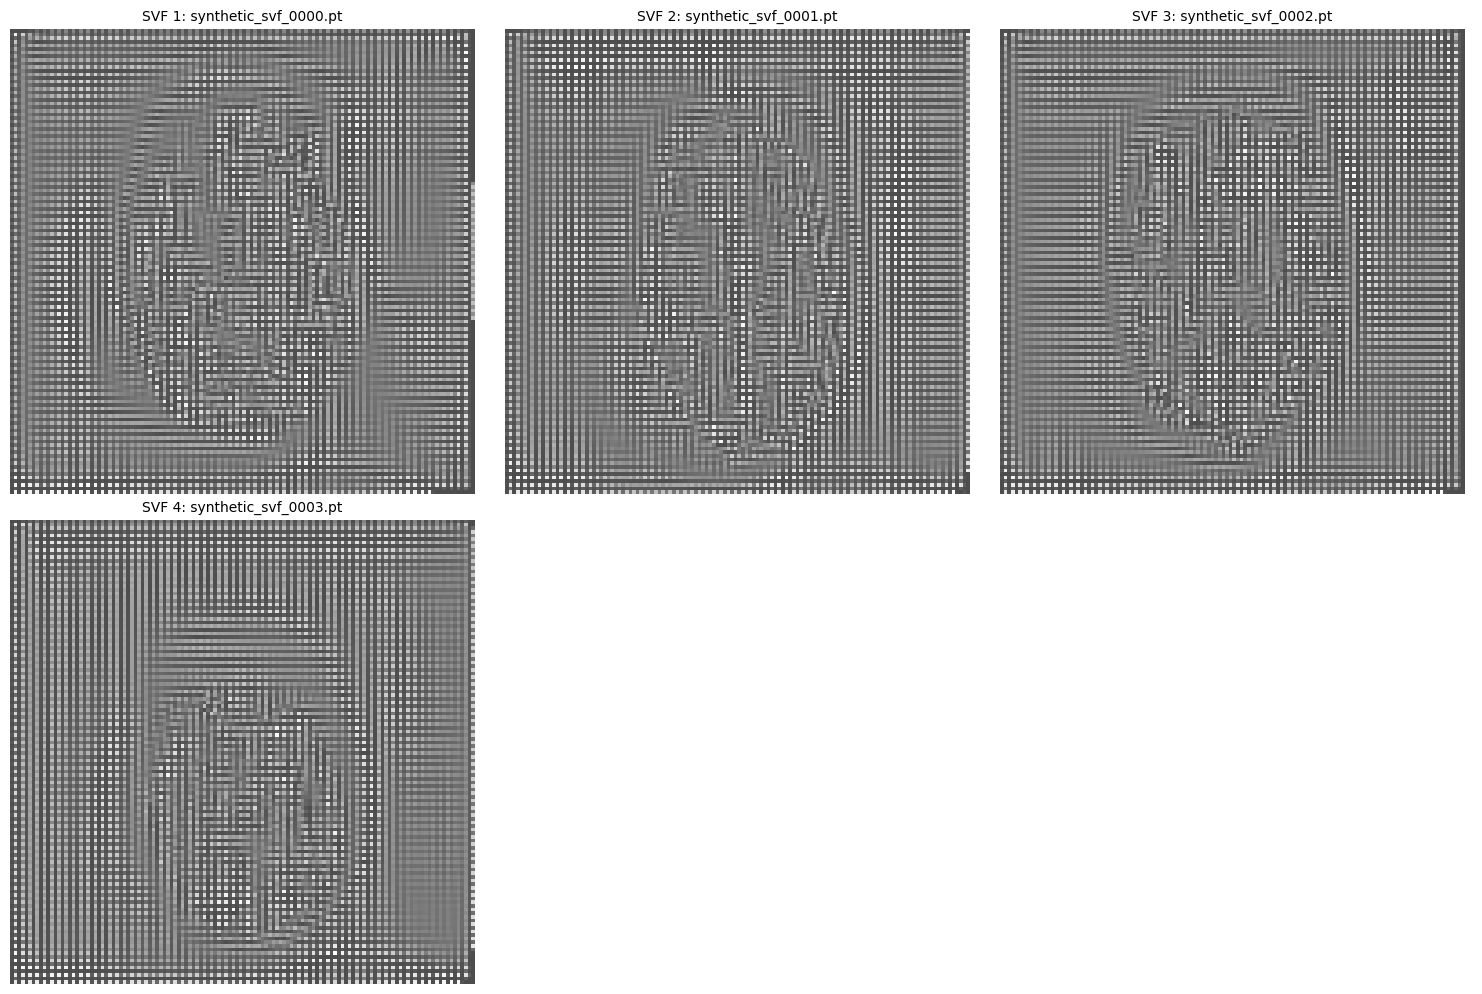

In [3]:
# Example usage in Jupyter notebook:
# Just add the following lines to a cell after your SVF generation code:
#
# # For visualizing a single SVF
# fig = visualize_svf_file(list_svf[0])
# plt.show()
#
# # For visualizing multiple SVFs in a grid
fig = visualize_multiple_svfs(list_svf[:4])
plt.show()

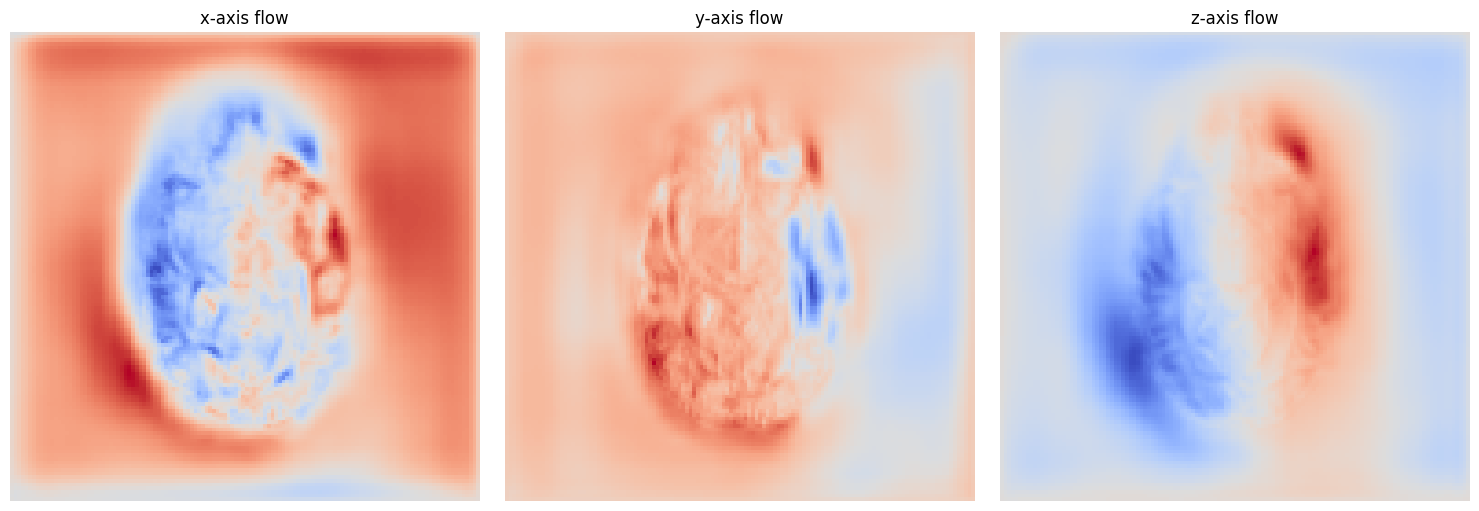

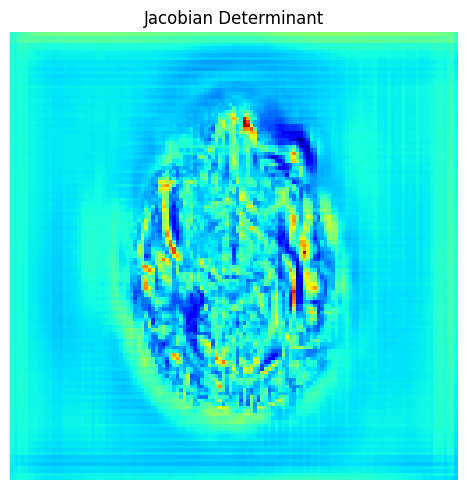

In [7]:
import torch

# path_to_svf = "/scratch/anirudhkaushik/synthetic_deformations/synthetic_svf_0001.pt"
from losses import jacobian_determinant_torch
real_svf = torch.load(real_path)
svf = list_svf[0]
svf = torch.load(svf)
# Convert to numpy array
svf_np = svf.numpy()
# Assuming svf is a 4D tensor of shape [3, H, W, D]
# Pick a slice index for visualization
slice_idx = svf_np.shape[2] // 2  # middle slice along the depth


# Plot the central slice of each component
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
titles = ['x-axis flow', 'y-axis flow', 'z-axis flow']

for i in range(3):
    axes[i].imshow(svf_np[i, :, :, slice_idx], cmap='coolwarm')
    axes[i].set_title(titles[i])
    axes[i].axis('off')

plt.tight_layout()
plt.show()

jac_det = jacobian_determinant_torch(svf.unsqueeze(0))  # Remove batch dimension
# Convert to numpy array
jac_det_np = jac_det.squeeze().numpy()
# Plot the Jacobian determinant
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(jac_det_np[:, :, slice_idx], cmap='jet')
ax.set_title('Jacobian Determinant')
ax.axis('off')



plt.tight_layout()
plt.show()

In [5]:
import torch
import numpy as np
import os
from PIL import Image
from matplotlib import cm
from losses import jacobian_determinant_torch

# Create output directory if not exists
os.makedirs('./image_results', exist_ok=True)

# Load real SVF
real_svf = torch.load(real_path)
real_svf_np = real_svf.numpy()
slice_idx = real_svf_np.shape[2] // 2  # middle slice

# Function to normalize and convert array to image
def array_to_image(array, colormap='coolwarm'):
    # Normalize to 0-1 range
    norm_array = (array - array.min()) / (array.max() - array.min())
    
    # Apply colormap
    colored_array = (cm.get_cmap(colormap)(norm_array) * 255).astype(np.uint8)
    
    # Convert to RGB (remove alpha channel)
    return colored_array[:, :, :3]

# Save real SVF components
for i in range(3):
    component = real_svf_np[i, :, :, slice_idx]
    img_array = array_to_image(component)
    img = Image.fromarray(img_array)
    img.save(f'./image_results/real_svf_component_{i}.png')

# Calculate and save Jacobian determinant for real SVF
real_jac_det = jacobian_determinant_torch(real_svf.unsqueeze(0))
real_jac_det_np = real_jac_det.squeeze().numpy()
jac_img_array = array_to_image(real_jac_det_np[:, :, slice_idx], 'jet')
jac_img = Image.fromarray(jac_img_array)
jac_img.save('./image_results/real_svf_jacobian.png')

# Process all synthetic SVFs
for idx, svf_path in enumerate(list_svf):
    svf = torch.load(svf_path)
    svf_np = svf.numpy()
    
    # Save components
    for i in range(3):
        component = svf_np[i, :, :, slice_idx]
        img_array = array_to_image(component)
        img = Image.fromarray(img_array)
        img.save(f'./image_results/synthetic_svf_{idx}_component_{i}.png')
    
    # Calculate and save Jacobian
    jac_det = jacobian_determinant_torch(svf.unsqueeze(0))
    jac_det_np = jac_det.squeeze().numpy()
    jac_img_array = array_to_image(jac_det_np[:, :, slice_idx], 'jet')
    jac_img = Image.fromarray(jac_img_array)
    jac_img.save(f'./image_results/synthetic_svf_{idx}_jacobian.png')

print(f"Saved all images to ./image_results/")

/tmp/ipykernel_39812/3818110620.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colored_array = (cm.get_cmap(colormap)(norm_array) * 255).astype(np.uint8)


Saved all images to ./image_results/


In [6]:
svf_list = ["941_S_1202_sc_m06.pt","941_S_1202_sc_m12.pt","941_S_1202_sc_m36.pt","941_S_1202_sc_m24.pt"]

for idx, svf in enumerate(svf_list):
    svf = os.path.join("/scratch/anirudhkaushik/svf_outputs/", svf)
    svf = torch.load(svf)
    svf_np = svf.numpy()
    # Assuming svf is a 4D tensor of shape [3, H, W, D]
    # Pick a slice index for visualization
    slice_idx = svf_np.shape[2] // 2  # middle slice along the depth

    # Plot the central slice of each component
    titles = ['x-axis flow', 'y-axis flow', 'z-axis flow']

    # save images of all three channels
    for i in range(3):
        component = svf_np[i, :, :, slice_idx]
        img_array = array_to_image(component)
        img = Image.fromarray(img_array)
        img.save(f'./image_results/real_model_svf_{idx}_component_{i}.png')
    


/tmp/ipykernel_39812/3818110620.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colored_array = (cm.get_cmap(colormap)(norm_array) * 255).astype(np.uint8)


In [7]:
import nibabel as nib

svf_list = ["ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948397_S46683_I105437_padded_transposed_padded_transposed_all_synthetic_field.nii.gz","ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948397_S46683_I105437_padded_transposed_padded_transposed_all_synthetic.nii.gz","ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948398_S38468_I75150_padded_transposed_padded_transposed_all_synthetic_field.nii.gz","ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948398_S38468_I75150_padded_transposed_padded_transposed_all_synthetic.nii.gz","ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948398_S81149_I204843_padded_transposed_padded_transposed_all_synthetic_field.nii.gz","ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948398_S81149_I204843_padded_transposed_padded_transposed_all_synthetic.nii.gz","ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948399_S63253_I137298_padded_transposed_padded_transposed_all_synthetic_field.nii.gz","ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948399_S63253_I137298_padded_transposed_padded_transposed_all_synthetic.nii.gz"]
for idx, svf in enumerate(svf_list):
    if not "_synthetic_field.nii.gz" in svf:
        continue
    svf = os.path.join("/scratch/anirudhkaushik/SYNBADD_Qualitative_1/SYNBADD_128_6_5e-05_0.0_2025-04-16_04-59-48_ADNI_all_longitudinal_FinalVAETransformer_Vanilla_Fold1/", svf)
    svf = nib.load(svf)
    svf_np = svf.get_fdata()
    print(svf.shape)
    # Assuming svf is a 4D tensor of shape [3, H, W, D]
    # Pick a slice index for visualization
    slice_idx = svf_np.shape[2] // 2  # middle slice along the depth

    # Plot the central slice of each component
    titles = ['x-axis flow', 'y-axis flow', 'z-axis flow']

    # save images of all three channels
    for i in range(3):
        component = svf_np[i, :, :, slice_idx]
        img_array = array_to_image(component)
        img = Image.fromarray(img_array)
        img.save(f'./image_results/generated_model_svf_{idx}_component_{i}.png')
    


(3, 128, 128, 128)
(3, 128, 128, 128)


/tmp/ipykernel_39812/3818110620.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colored_array = (cm.get_cmap(colormap)(norm_array) * 255).astype(np.uint8)


(3, 128, 128, 128)
(3, 128, 128, 128)


In [11]:
img = nib.load("/scratch/anirudhkaushik/ADNI_Resized_Registered/ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948399_S25680_I63874_padded_transposed_padded_transposed.nii.gz")
img_np = img.get_fdata()
img_np = img_np[:, :, img_np.shape[2] // 2]
img_np = array_to_image(img_np, 'gray')
img = Image.fromarray(img_np)
img.save(f'./image_results/baseline_image.png')

/tmp/ipykernel_39812/3818110620.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colored_array = (cm.get_cmap(colormap)(norm_array) * 255).astype(np.uint8)


In [12]:
img = nib.load("/scratch/anirudhkaushik/SYNBADD_Qualitative_1/SYNBADD_128_6_5e-05_0.0_2025-04-16_04-59-48_ADNI_all_longitudinal_FinalVAETransformer_Vanilla_Fold1/ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948397_S46683_I105437_padded_transposed_padded_transposed_all_synthetic.nii.gz")
img_np = img.get_fdata().squeeze(0)
img_np = img_np[:, :, img_np.shape[2] // 2]
img_np = array_to_image(img_np, 'gray')
img = Image.fromarray(img_np)
img.save(f'./image_results/predicted_m12_image.png')

/tmp/ipykernel_39812/3818110620.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colored_array = (cm.get_cmap(colormap)(norm_array) * 255).astype(np.uint8)


Figure saved as model_comparison.pdf


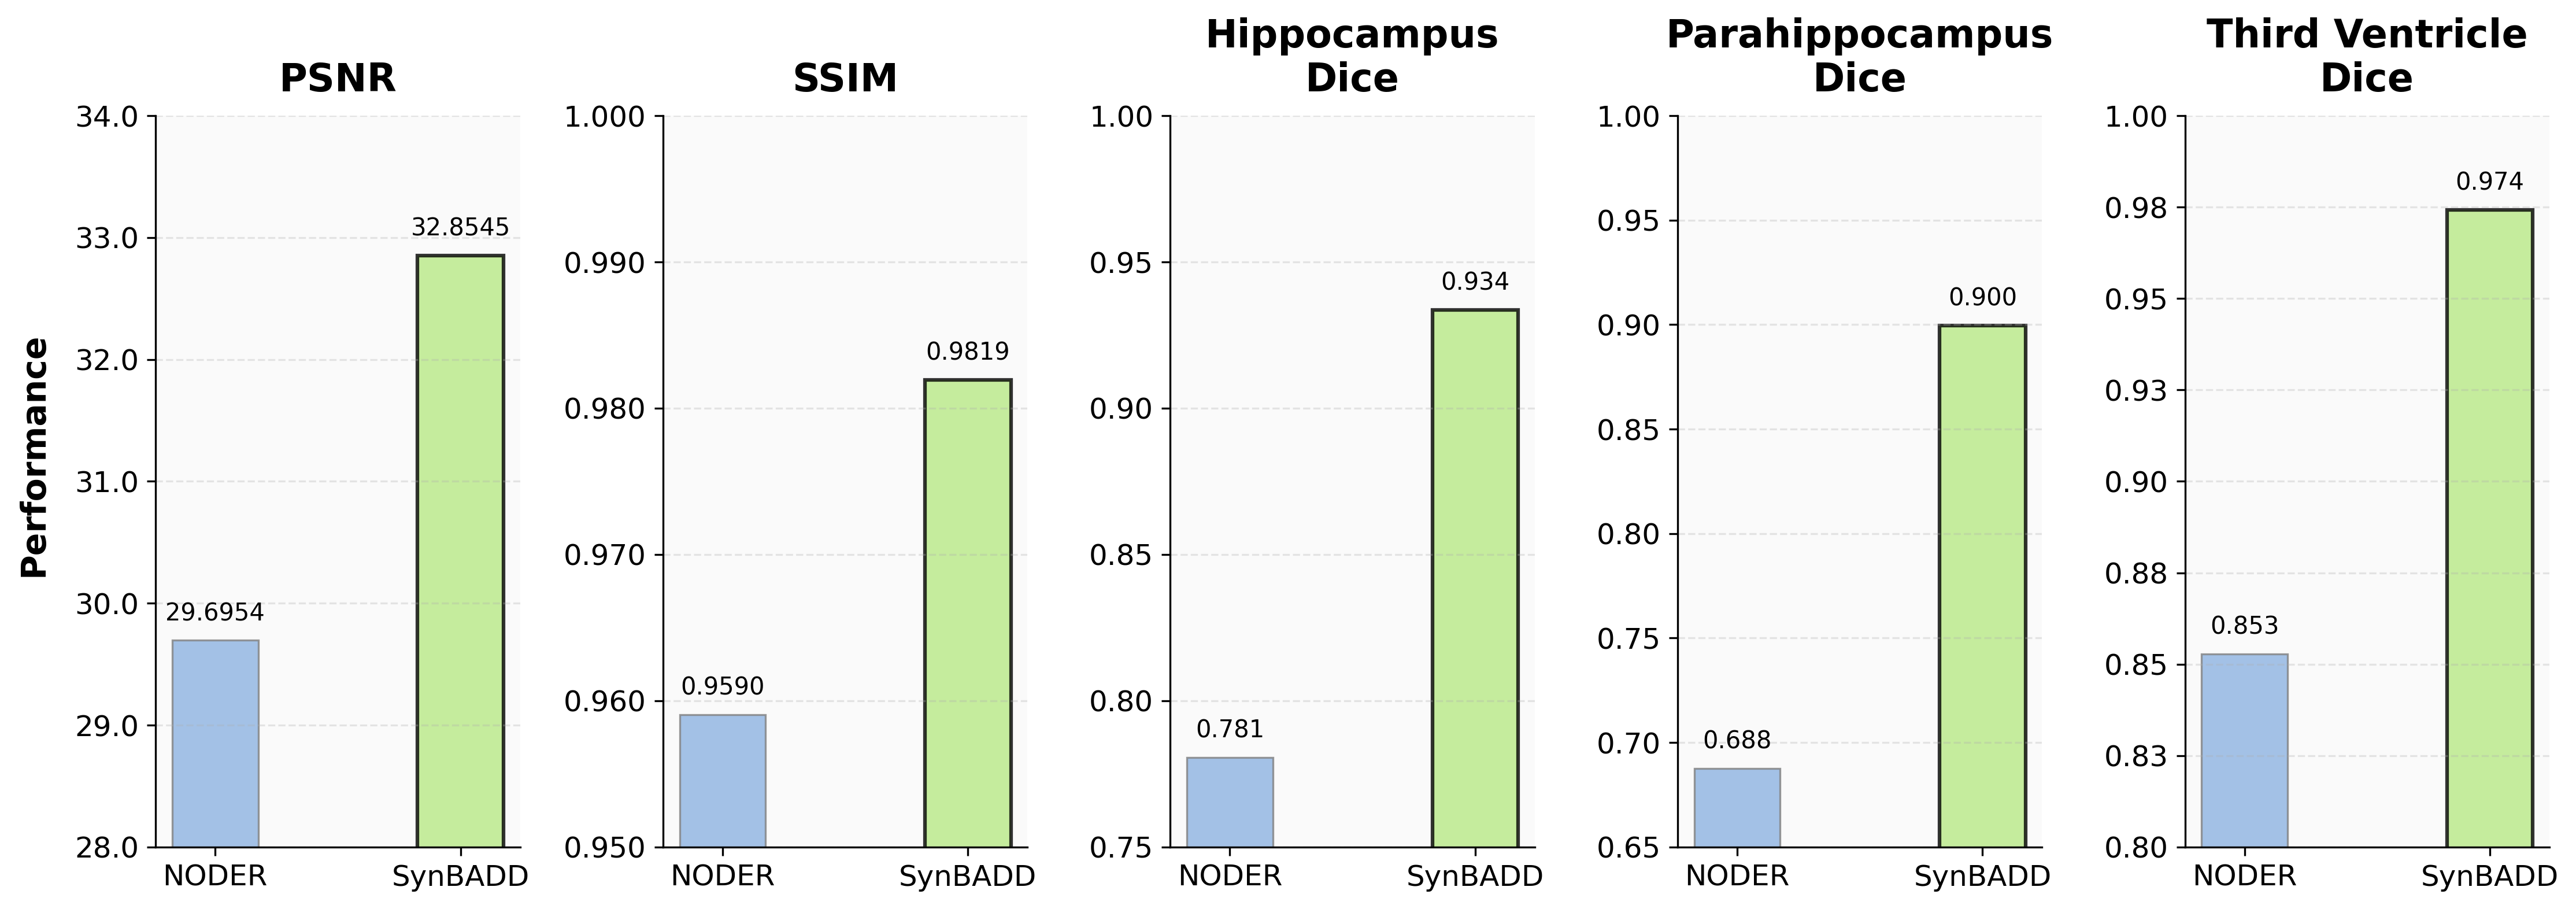

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker
from matplotlib.patches import Rectangle

def generate_comparison_figure(output_filename="model_comparison.pdf"):
    """
    Generate a clean PDF figure comparing NODER and SynBADD models
    on various metrics with soft pastel colors and adjusted axes.
    
    Parameters:
    ----------
    output_filename : str
        Filename for the output PDF figure
    """
    # Set up data
    metrics = ['PSNR', 'SSIM', 'Hippocampus\nDice', 'Parahippocampus\nDice', 'Third Ventricle\nDice']
    noder_values = [29.69536332, 0.9590430256, 0.78056, 0.68754, 0.85276]
    synbadd_values = [32.8545248, 0.9819426, 0.93368, 0.89966, 0.97424]
    
    # Set up plot style
    plt.style.use('seaborn-v0_8-pastel')
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.size': 12,
        'font.weight': 'regular',
        'axes.labelweight': 'bold',
        'axes.titleweight': 'bold',
        'axes.labelsize': 14,
        'axes.titlesize': 16,
        'xtick.labelsize': 12,
        'ytick.labelsize': 12
    })
    
    # Create figure with appropriate size and DPI
    fig, axes = plt.subplots(1, 5, figsize=(15, 6), dpi=300)
    
    # Soft pastel colors
    noder_color = "#8db3e2"  # Soft blue
    synbadd_color = "#b8e986"  # Soft green
    background_color = "#fafafa"  # Very light gray
    
    # Create custom y-axis ranges for each metric
    y_ranges = [
        (28, 34),       # PSNR
        (0.95, 1.0),    # SSIM
        (0.75, 1.0),    # Hippocampus
        (0.65, 1.0),    # Parahippocampus
        (0.8, 1.0)      # Third Ventricle
    ]
    
    # For bar width calculations
    width = 0.35
    
    # Plot each metric
    for i, (metric, noder, synbadd, y_range) in enumerate(zip(metrics, noder_values, synbadd_values, y_ranges)):
        ax = axes[i]
        
        # Set light background
        ax.set_facecolor(background_color)
        
        # Create bars
        x = np.array([0, 1])
        bars = ax.bar(x, [noder, synbadd], width=width, color=[noder_color, synbadd_color], 
                     edgecolor='gray', linewidth=0.8, alpha=0.8)
        
        # Add value labels on top of bars
        for j, bar in enumerate(bars):
            height = bar.get_height()
            value = noder if j == 0 else synbadd
            ax.text(bar.get_x() + bar.get_width()/2., height + (y_range[1]-y_range[0])*0.02,
                   f'{value:.4f}' if metric == 'PSNR' or metric == 'SSIM' else f'{value:.3f}',
                   ha='center', va='bottom', fontsize=10, rotation=0)
        
        # Highlight the better value
        better_idx = 0 if noder > synbadd else 1
        bars[better_idx].set_edgecolor('black')
        bars[better_idx].set_linewidth(1.5)
        
        # Add text labels to x-axis
        ax.set_xticks(x)
        ax.set_xticklabels(['NODER', 'SynBADD'])
        
        # Set y-axis range and title
        ax.set_ylim(y_range)
        ax.set_title(metric, fontweight='bold', pad=10)
        
        # Format y-axis based on metric
        if metric == 'PSNR':
            ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))
        elif metric == 'SSIM':
            ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.3f'))
        else:
            ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
        
        # Grid lines for easier reading
        ax.grid(axis='y', linestyle='--', alpha=0.3)
        
        # Remove top and right spines
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    
    # Add a common y-axis label
    fig.text(0.01, 0.5, 'Performance', va='center', rotation='vertical', fontsize=14, fontweight='bold')
    
    # Add a title for the entire figure
    # plt.suptitle('Model Performance Comparison: NODER vs SynBADD', fontsize=18, y=0.98)
    
    # Add explanation text
    # fig.text(0.5, 0.02, 'Higher values are better for all metrics', ha='center', 
            # fontsize=12, fontstyle='italic')
    
    # Adjust layout
    plt.tight_layout(rect=[0.02, 0.05, 1, 0.95])
    
    # Save figure
    plt.savefig(output_filename, format='pdf', bbox_inches='tight', dpi=300)
    print(f"Figure saved as {output_filename}")
    
    return fig

# Example usage
if __name__ == "__main__":
    fig = generate_comparison_figure()
    plt.show()

Figure saved as model_comparison.pdf


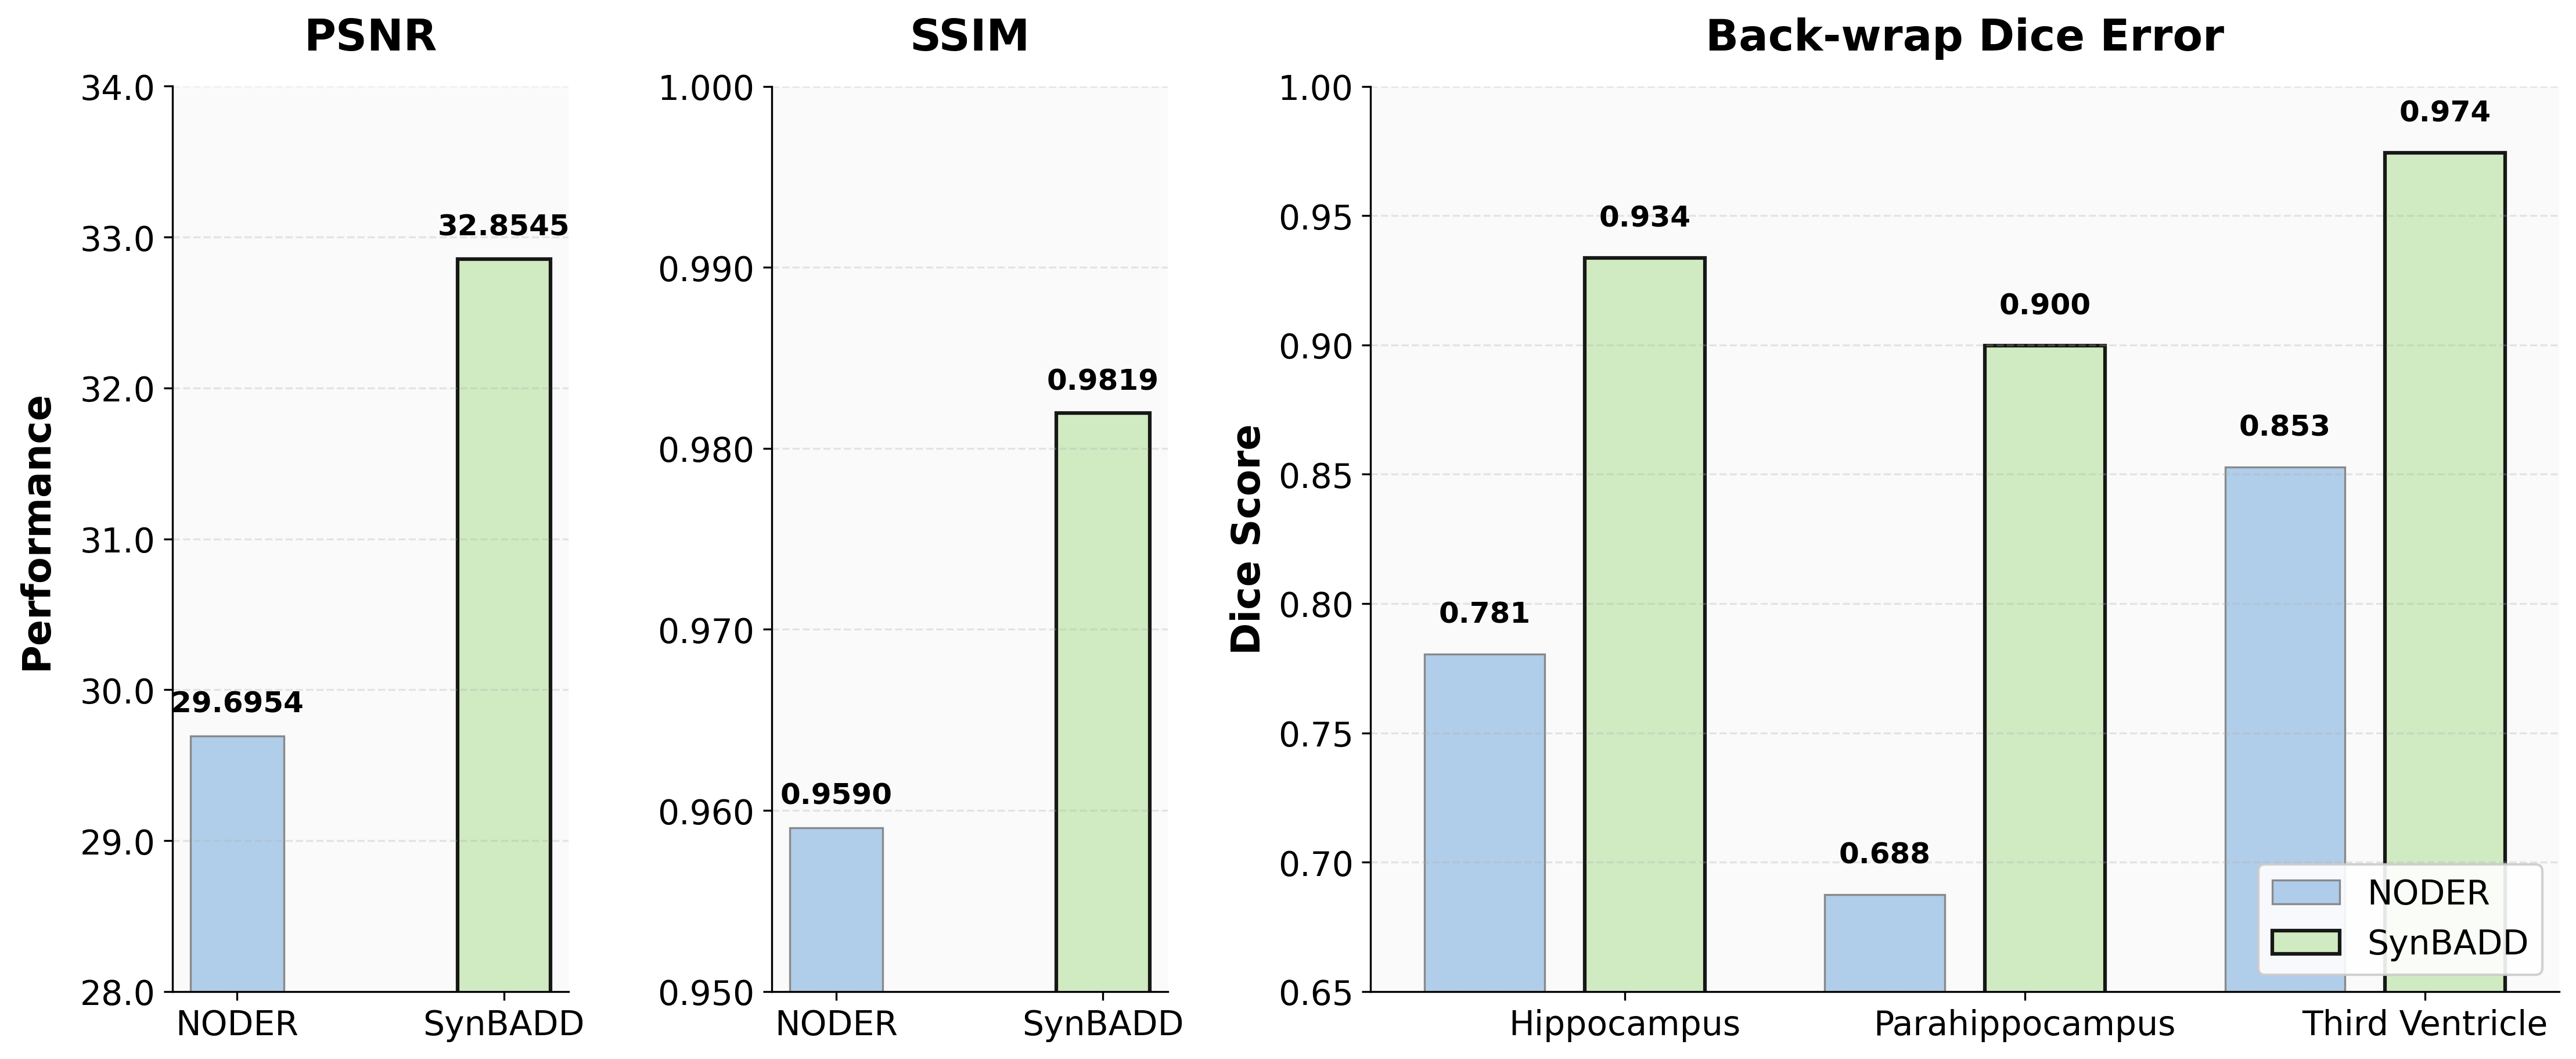

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker
from matplotlib.patches import Rectangle

def generate_comparison_figure(output_filename="model_comparison.pdf"):
    """
    Generate a clean PDF figure comparing NODER and SynBADD models
    with PSNR and SSIM as individual plots and Dice scores grouped together.
    Uses soft pastel colors with adjusted axes and larger fonts.
    
    Parameters:
    ----------
    output_filename : str
        Filename for the output PDF figure
    """
    # Set up data
    # For individual metrics
    metrics_individual = ['PSNR', 'SSIM']
    noder_individual = [29.69536332, 0.9590430256]
    synbadd_individual = [32.8545248, 0.9819426]
    
    # For grouped Dice metrics
    metrics_grouped = ['Hippocampus', 'Parahippocampus', 'Third Ventricle']
    noder_grouped = [0.78056, 0.68754, 0.85276]
    synbadd_grouped = [0.93368, 0.89966, 0.97424]
    
    # Set up plot style with larger fonts
    plt.style.use('seaborn-v0_8-pastel')
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.size': 14,  # Increased base font size
        'font.weight': 'regular',
        'axes.labelweight': 'bold',
        'axes.titleweight': 'bold',
        'axes.labelsize': 16,  # Increased label size
        'axes.titlesize': 18,  # Increased title size
        'xtick.labelsize': 14,  # Increased tick label size
        'ytick.labelsize': 14   # Increased tick label size
    })
    
    # Create figure with appropriate size and DPI
    fig, axes = plt.subplots(1, 3, figsize=(15, 7), dpi=300, gridspec_kw={'width_ratios': [1, 1, 3]})
    
    # Softer pastel colors
    noder_color = "#a8c8e8"  # Milder soft blue
    synbadd_color = "#cce9bc"  # Milder soft green
    background_color = "#fafafa"  # Very light gray
    
    # Create custom y-axis ranges for each metric
    y_ranges_individual = [
        (28, 34),       # PSNR
        (0.95, 1.0),    # SSIM
    ]
    
    # For bar width calculations
    width = 0.35
    
    # Plot individual metrics (PSNR and SSIM)
    for i, (metric, noder, synbadd, y_range) in enumerate(zip(metrics_individual, noder_individual, synbadd_individual, y_ranges_individual)):
        ax = axes[i]
        
        # Set light background
        ax.set_facecolor(background_color)
        
        # Create bars
        x = np.array([0, 1])
        bars = ax.bar(x, [noder, synbadd], width=width, color=[noder_color, synbadd_color], 
                     edgecolor='gray', linewidth=0.8, alpha=0.9)
        
        # Add value labels on top of bars
        for j, bar in enumerate(bars):
            height = bar.get_height()
            value = noder if j == 0 else synbadd
            ax.text(bar.get_x() + bar.get_width()/2., height + (y_range[1]-y_range[0])*0.02,
                   f'{value:.4f}',
                   ha='center', va='bottom', fontsize=12, rotation=0, fontweight='bold')
        
        # Highlight the better value
        better_idx = 0 if noder > synbadd else 1
        bars[better_idx].set_edgecolor('black')
        bars[better_idx].set_linewidth(1.5)
        
        # Add text labels to x-axis
        ax.set_xticks(x)
        ax.set_xticklabels(['NODER', 'SynBADD'])
        
        # Set y-axis range and title
        ax.set_ylim(y_range)
        ax.set_title(metric, fontweight='bold', pad=15)
        
        # Format y-axis based on metric
        if metric == 'PSNR':
            ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))
        else:  # SSIM
            ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.3f'))
        
        # Grid lines for easier reading
        ax.grid(axis='y', linestyle='--', alpha=0.3)
        
        # Remove top and right spines
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    
    # Plot grouped Dice metrics
    ax = axes[2]
    ax.set_facecolor(background_color)
    
    # Setup for grouped bar chart with more spacing between groups
    x = np.arange(len(metrics_grouped))
    width = 0.3  # Reduce width for less crowding
    
    # Create grouped bars with more spacing
    rects1 = ax.bar(x - width - 0.05, noder_grouped, width, label='NODER', 
                   color=noder_color, edgecolor='gray', linewidth=0.8, alpha=0.9)
    rects2 = ax.bar(x + 0.05, synbadd_grouped, width, label='SynBADD', 
                   color=synbadd_color, edgecolor='gray', linewidth=0.8, alpha=0.9)
    
    # Add value labels on top of bars
    for rect in rects1:
        height = rect.get_height()
        ax.text(rect.get_x() + rect.get_width()/2., height + 0.01,
               f'{height:.3f}', ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    for rect in rects2:
        height = rect.get_height()
        ax.text(rect.get_x() + rect.get_width()/2., height + 0.01,
               f'{height:.3f}', ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    # Highlight better values (always SynBADD in this case)
    for rect in rects2:
        rect.set_edgecolor('black')
        rect.set_linewidth(1.5)
    
    # Set labels and title
    ax.set_ylabel('Dice Score', fontweight='bold')
    ax.set_title('Back-wrap Dice Error', fontweight='bold', pad=15)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics_grouped)
    ax.set_ylim(0.65, 1.0)
    
    # Add legend
    ax.legend(loc='lower right', frameon=True, framealpha=0.9)
    
    # Grid lines
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    
    # Remove top and right spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Add a common y-axis label for first two plots
    fig.text(0.01, 0.5, 'Performance', va='center', rotation='vertical', fontsize=16, fontweight='bold')
    
    # Add a title for the entire figure
    
    # Add more space for the Dice plot by adjusting subplot spacing
    plt.subplots_adjust(wspace=0.3)
    
    # Add explanation text
    
    # Adjust layout
    plt.tight_layout(rect=[0.02, 0.05, 1, 0.95])
    
    # Save figure
    plt.savefig(output_filename, format='pdf', bbox_inches='tight', dpi=300)
    print(f"Figure saved as {output_filename}")
    
    return fig

# Example usage
if __name__ == "__main__":
    fig = generate_comparison_figure()
    plt.show()

Figure saved as model_comparison.pdf


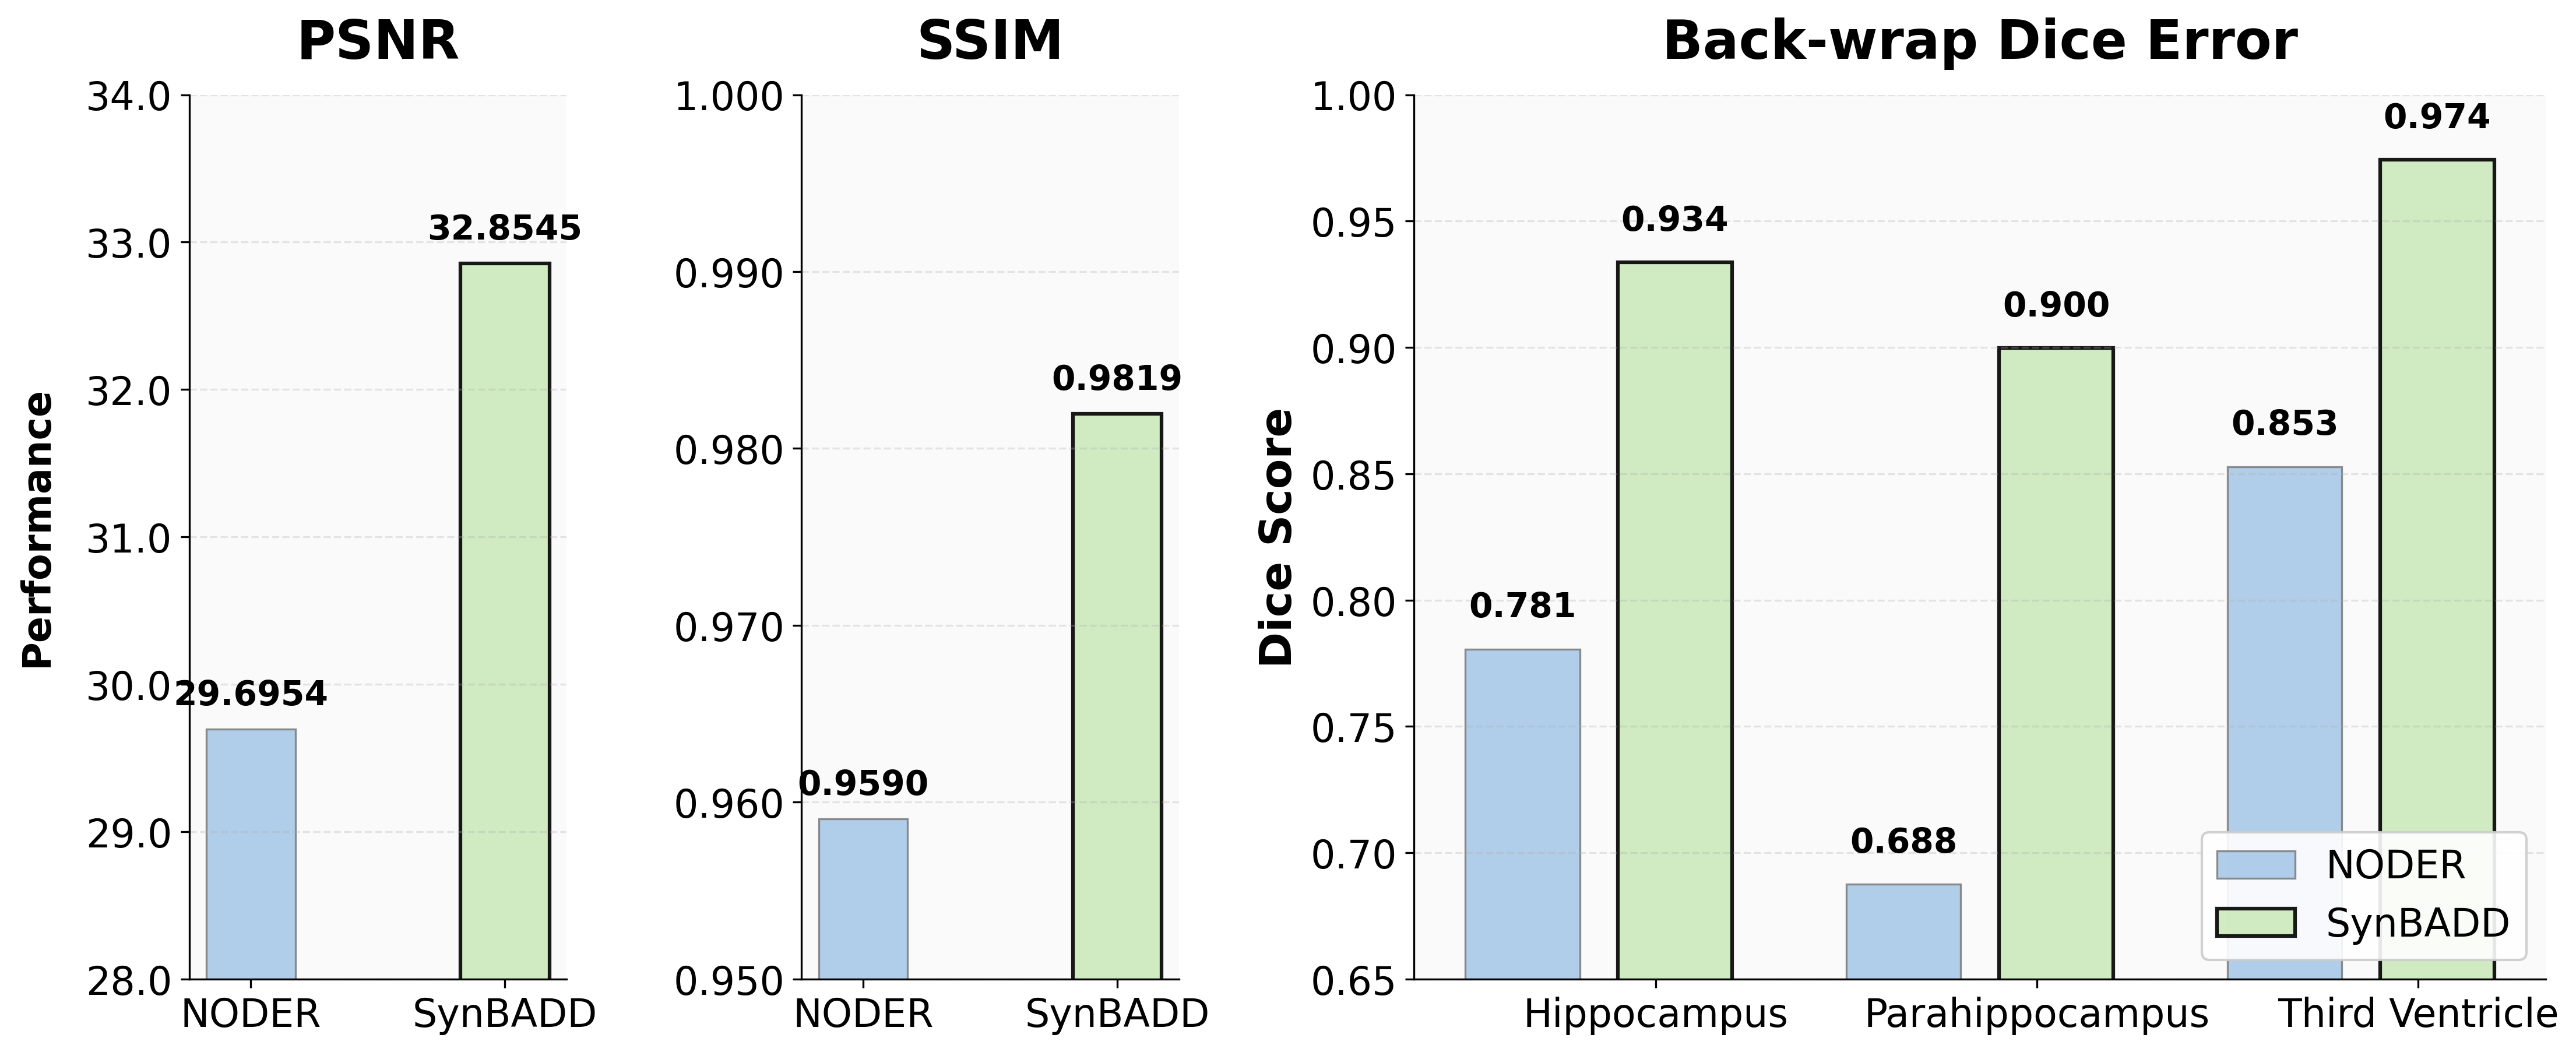

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker
from matplotlib.patches import Rectangle

def generate_comparison_figure(output_filename="model_comparison.pdf"):
    """
    Generate a clean PDF figure comparing NODER and SynBADD models
    with PSNR and SSIM as individual plots and Dice scores grouped together.
    Uses soft pastel colors with adjusted axes and larger fonts.
    
    Parameters:
    ----------
    output_filename : str
        Filename for the output PDF figure
    """
    # Set up data
    # For individual metrics
    metrics_individual = ['PSNR', 'SSIM']
    noder_individual = [29.6954, 0.959]
    synbadd_individual = [32.854, 0.982]
    
    # For grouped Dice metrics
    metrics_grouped = ['Hippocampus', 'Parahippocampus', 'Third Ventricle']
    noder_grouped = [0.7806, 0.6875, 0.8528]
    synbadd_grouped = [0.9337, 0.8997, 0.9742]
    
    # Set up plot style with even larger fonts
    plt.style.use('seaborn-v0_8-pastel')
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.size': 16,  # Increased base font size
        'font.weight': 'regular',
        'axes.labelweight': 'bold',
        'axes.titleweight': 'bold',
        'axes.labelsize': 18,  # Increased label size
        'axes.titlesize': 22,  # Increased title size
        'xtick.labelsize': 16,  # Increased tick label size
        'ytick.labelsize': 16   # Increased tick label size
    })
    
    # Create figure with appropriate size and DPI
    fig, axes = plt.subplots(1, 3, figsize=(15, 7), dpi=300, gridspec_kw={'width_ratios': [1, 1, 3]})
    
    # Softer pastel colors
    noder_color = "#a8c8e8"  # Milder soft blue
    synbadd_color = "#cce9bc"  # Milder soft green
    background_color = "#fafafa"  # Very light gray
    
    # Create custom y-axis ranges for each metric
    y_ranges_individual = [
        (28, 34),       # PSNR
        (0.95, 1.0),    # SSIM
    ]
    
    # For bar width calculations
    width = 0.35
    
    # Plot individual metrics (PSNR and SSIM)
    for i, (metric, noder, synbadd, y_range) in enumerate(zip(metrics_individual, noder_individual, synbadd_individual, y_ranges_individual)):
        ax = axes[i]
        
        # Set light background
        ax.set_facecolor(background_color)
        
        # Create bars
        x = np.array([0, 1])
        bars = ax.bar(x, [noder, synbadd], width=width, color=[noder_color, synbadd_color], 
                     edgecolor='gray', linewidth=0.8, alpha=0.9)
        
        # Add value labels on top of bars
        for j, bar in enumerate(bars):
            height = bar.get_height()
            value = noder if j == 0 else synbadd
            ax.text(bar.get_x() + bar.get_width()/2., height + (y_range[1]-y_range[0])*0.02,
                   f'{value:.4f}',
                   ha='center', va='bottom', fontsize=14, rotation=0, fontweight='bold')
        
        # Highlight the better value
        better_idx = 0 if noder > synbadd else 1
        bars[better_idx].set_edgecolor('black')
        bars[better_idx].set_linewidth(1.5)
        
        # Add text labels to x-axis
        ax.set_xticks(x)
        ax.set_xticklabels(['NODER', 'SynBADD'])
        
        # Set y-axis range and title
        ax.set_ylim(y_range)
        ax.set_title(metric, fontweight='bold', pad=15)
        
        # Format y-axis based on metric
        if metric == 'PSNR':
            ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))
        else:  # SSIM
            ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.3f'))
        
        # Grid lines for easier reading
        ax.grid(axis='y', linestyle='--', alpha=0.3)
        
        # Remove top and right spines
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    
    # Plot grouped Dice metrics
    ax = axes[2]
    ax.set_facecolor(background_color)
    
    # Setup for grouped bar chart with more spacing between groups
    x = np.arange(len(metrics_grouped))
    width = 0.3  # Reduce width for less crowding
    
    # Create grouped bars with more spacing
    rects1 = ax.bar(x - width - 0.05, noder_grouped, width, label='NODER', 
                   color=noder_color, edgecolor='gray', linewidth=0.8, alpha=0.9)
    rects2 = ax.bar(x + 0.05, synbadd_grouped, width, label='SynBADD', 
                   color=synbadd_color, edgecolor='gray', linewidth=0.8, alpha=0.9)
    
    # Add value labels on top of bars
    for rect in rects1:
        height = rect.get_height()
        ax.text(rect.get_x() + rect.get_width()/2., height + 0.01,
               f'{height:.3f}', ha='center', va='bottom', fontsize=14, fontweight='bold')
    
    for rect in rects2:
        height = rect.get_height()
        ax.text(rect.get_x() + rect.get_width()/2., height + 0.01,
               f'{height:.3f}', ha='center', va='bottom', fontsize=14, fontweight='bold')
    
    # Highlight better values (always SynBADD in this case)
    for rect in rects2:
        rect.set_edgecolor('black')
        rect.set_linewidth(1.5)
    
    # Set labels and title
    ax.set_ylabel('Dice Score', fontweight='bold')
    ax.set_title('Back-wrap Dice Error', fontweight='bold', pad=15)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics_grouped)
    ax.set_ylim(0.65, 1.0)
    
    # Add legend
    ax.legend(loc='lower right', frameon=True, framealpha=0.9)
    
    # Grid lines
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    
    # Remove top and right spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Add a common y-axis label for first two plots
    fig.text(0.01, 0.5, 'Performance', va='center', rotation='vertical', fontsize=16, fontweight='bold')
    
    # Add a title for the entire figure
    
    # Add more space for the Dice plot by adjusting subplot spacing
    plt.subplots_adjust(wspace=0.3)
    
    # Add explanation text
    
    # Adjust layout
    plt.tight_layout(rect=[0.02, 0.05, 1, 0.95])
    
    # Save figure
    plt.savefig(output_filename, format='pdf', bbox_inches='tight', dpi=300)
    print(f"Figure saved as {output_filename}")
    
    return fig

# Example usage
if __name__ == "__main__":
    fig = generate_comparison_figure()
    plt.show()